# Buổi G1: Mạng nơ-ron, xếp nhiều hồi quy logistic chồng lên nhau

**Hiện trường.** Chị Hạnh muốn đoán khách có **quay lại** cửa hàng không, dựa trên hai con số. Khi vẽ ra, khách quay lại và không quay lại **đan xen theo đường cong** (như hai hình trăng lồng nhau). Hồi quy logistic (C1) chỉ vẽ được **một đường thẳng** nên chia sai nhiều. Chị cần mô hình uốn được đường ranh giới.

Buổi này dạy **mạng nơ-ron nhiều lớp** (*multilayer perceptron*, MLP): xếp **nhiều hồi quy logistic** thành một tầng (tầng ẩn), rồi lấy kết quả của chúng làm đầu vào cho một hồi quy logistic nữa. Mỗi "nơ-ron" chỉ là một phép tính quen thuộc; cái mới là xếp chồng và **bẻ cong** giữa các tầng.

**Ẩn dụ:** một người chỉ vẽ được đường thẳng. Tám người, mỗi người vẽ một đường thẳng của mình, rồi một "trưởng nhóm" nghe cả tám và quyết định theo cách riêng: đường ranh giới cuối cùng là **tổ hợp của tám đường thẳng**, nên uốn cong được.

**Mindset của người làm dữ liệu:** mạng nơ-ron không phải phép màu. Nó là hàm có nhiều núm vặn (trọng số), được chỉnh dần bằng cách **đo sai số rồi chỉnh theo hướng giảm sai số**. Nhiều núm vặn thì uốn được nhiều, và cũng dễ học thừa (D2).

**Lưu ý:** dữ liệu `make_moons` dựng có chủ đích để thấy đường cong; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: đường thẳng thua, mạng nơ-ron uốn được |
| Chặng 1 | Mở hộp: tự tính tiến tới bằng trọng số của sklearn |
| Chặng 2 | Tự huấn luyện một mạng nhỏ bằng numpy (lan truyền ngược) |
| Chặng 3 | Hàm kích hoạt: không có nó thì mạng chỉ là đường thẳng |
| Chặng 4 | Bao nhiêu nơ-ron là đủ |
| Chặng 5 | Bẫy thang đo và hạt giống |

## Chặng 0: Thấy ngay, đường thẳng thua

**Câu hỏi:** cùng dữ liệu hai hình trăng, hồi quy logistic và mạng nơ-ron khác nhau thế nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

logistic test accuracy: 0.838 | MLP (8 neurons) test accuracy: 0.95


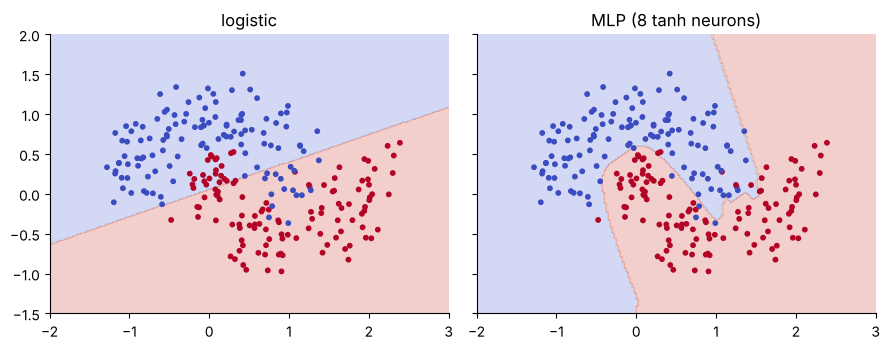

In [2]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
X, y = make_moons(n_samples=800, noise=0.25, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
logit = LogisticRegression().fit(X_train, y_train)
mlp = MLPClassifier(hidden_layer_sizes=(8,), activation="tanh", solver="lbfgs", max_iter=2000, random_state=0).fit(X_train, y_train)
print("logistic test accuracy:", round(logit.score(X_test, y_test), 3), "| MLP (8 neurons) test accuracy:", round(mlp.score(X_test, y_test), 3))
gx, gy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
grid = np.c_[gx.ravel(), gy.ravel()]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for a, model, name in zip(ax, [logit, mlp], ["logistic", "MLP (8 tanh neurons)"]):
    a.contourf(gx, gy, model.predict(grid).reshape(gx.shape), alpha=0.25, cmap="coolwarm")
    a.scatter(*X_test.T, c=y_test, cmap="coolwarm", s=10); a.set_title(name)
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `make_moons(n_samples=800, noise=0.25)`: hai hình trăng lồng nhau, có nhiễu vừa phải. Dữ liệu dựng có chủ đích.
- `MLPClassifier(hidden_layer_sizes=(8,), activation="tanh", max_iter=2000)`: mạng có **một tầng ẩn 8 nơ-ron**, hàm kích hoạt `tanh` (chặng 3). `max_iter` là số vòng huấn luyện tối đa.
- `solver="lbfgs"`: cách chỉnh trọng số. `lbfgs` hợp với dữ liệu nhỏ (vài trăm đến vài nghìn dòng): hội tụ nhanh và ổn định hơn `adam` mặc định, vốn được thiết kế cho dữ liệu lớn và hay dừng sớm khi dữ liệu nhỏ.
- `np.meshgrid(...)`: lưới 200 x 200 điểm phủ kín mặt phẳng, để tô vùng mô hình đoán "quay lại" hay "không".
- `contourf(..., model.predict(grid))`: tô màu vùng quyết định. Đường ranh giữa hai màu chính là đường chia của mô hình.

**Cách đọc.**
- **Con số:** hồi quy logistic đạt **83,8%** trên tập thi, mạng nơ-ron **95,0%**.
- **Bức tranh:** logistic vẽ một đường thẳng; mạng nơ-ron uốn đường ranh giữa theo hình trăng.
- **Câu hỏi tiếp:** bên trong "8 nơ-ron" thật sự tính gì? Ta tự tính lại.

**Mang về chặng 1:** mạng nơ-ron uốn được đường ranh giới mà đường thẳng không uốn được.

## Chặng 1: Mở hộp, tự tính tiến tới

**Câu hỏi:** từ hai con số của một khách, mạng ra xác suất bằng những phép tính nào?

In [3]:
W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_
print("shapes -> W1:", W1.shape, "b1:", b1.shape, "W2:", W2.shape, "b2:", b2.shape)
def forward(points):
    hidden = np.tanh(points @ W1 + b1)
    logit_out = hidden @ W2 + b2
    return 1 / (1 + np.exp(-logit_out)).ravel() if False else (1 / (1 + np.exp(-logit_out))).ravel()
mine = forward(X_test)
print("max difference with predict_proba:", float(np.abs(mine - mlp.predict_proba(X_test)[:, 1]).max()))
print("parameters in total:", W1.size + b1.size + W2.size + b2.size)

shapes -> W1: (2, 8) b1: (8,) W2: (8, 1) b2: (1,)
max difference with predict_proba: 8.673617379884035e-19
parameters in total: 33


**Giải thích từng dòng**

- `mlp.coefs_`: trọng số của từng tầng: `W1` là bảng 2 x 8 (mỗi nơ-ron ẩn nhận 2 đầu vào), `W2` là bảng 8 x 1.
- `points @ W1 + b1`: mỗi nơ-ron ẩn làm đúng việc của một hồi quy tuyến tính: nhân đầu vào với trọng số rồi cộng hằng số.
- `np.tanh(...)`: **hàm kích hoạt**: bẻ cong kết quả vào khoảng -1 đến 1.
- `hidden @ W2 + b2`: tầng ra: lại là hồi quy tuyến tính, nhưng đầu vào là 8 kết quả của tầng ẩn.
- `1 / (1 + np.exp(-x))`: hàm sigmoid ở C1: đổi số bất kỳ thành xác suất từ 0 đến 1.

**Cách đọc.**
- **Con số:** sai khác lớn nhất giữa bản tự tính và `predict_proba` là **8.7e-19**, tức trùng khớp. Cả mạng chỉ có **33** con số (trọng số và hằng số).
- **Bức tranh:** nơ-ron không có gì bí ẩn: một phép nhân cộng quen thuộc rồi một hàm bẻ cong. Chỗ mới là chồng hai tầng.
- **Câu hỏi tiếp:** 33 con số đó từ đâu ra? Máy chỉnh chúng thế nào?

**Mang về chặng 2:** mạng = nhân cộng, bẻ cong, nhân cộng, đổi thành xác suất.

## Chặng 2: Tự huấn luyện bằng numpy

**Câu hỏi:** làm sao tìm ra các trọng số đó?

loss at epoch 1 / 100 / 1000 / last: [0.751, 0.308, 0.149, 0.141]
my network test accuracy: 0.958 | sklearn MLP: 0.95


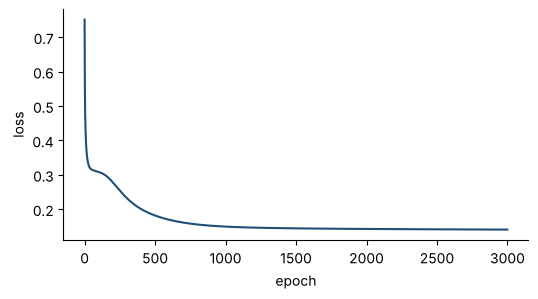

In [4]:
rng = np.random.RandomState(0)
n_hidden, lr, epochs = 8, 0.5, 3000
A1 = rng.randn(2, n_hidden) * 0.5; c1 = np.zeros(n_hidden)
A2 = rng.randn(n_hidden, 1) * 0.5; c2 = np.zeros(1)
yt = y_train.reshape(-1, 1).astype(float)
loss_curve = []
for epoch in range(epochs):
    h = np.tanh(X_train @ A1 + c1)
    p = 1 / (1 + np.exp(-(h @ A2 + c2)))
    loss = -np.mean(yt * np.log(p + 1e-9) + (1 - yt) * np.log(1 - p + 1e-9))
    loss_curve.append(float(loss))
    d_out = (p - yt) / len(yt)
    gA2 = h.T @ d_out; gc2 = d_out.sum(axis=0)
    d_h = (d_out @ A2.T) * (1 - h ** 2)
    gA1 = X_train.T @ d_h; gc1 = d_h.sum(axis=0)
    A1 -= lr * gA1; c1 -= lr * gc1; A2 -= lr * gA2; c2 -= lr * gc2
pred = (1 / (1 + np.exp(-(np.tanh(X_test @ A1 + c1) @ A2 + c2))) > 0.5).ravel().astype(int)
print("loss at epoch 1 / 100 / 1000 / last:", [round(loss_curve[i], 3) for i in (0, 99, 999, epochs - 1)])
print("my network test accuracy:", round((pred == y_test).mean(), 3), "| sklearn MLP:", round(mlp.score(X_test, y_test), 3))
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(loss_curve, color=BLUE); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); plt.show()

**Giải thích từng dòng**

- `rng.randn(2, n_hidden) * 0.5`: khởi đầu trọng số **ngẫu nhiên nhỏ**. Nếu cho tất cả bằng nhau thì mọi nơ-ron học y hệt nhau.
- `-np.mean(y * log(p) + (1 - y) * log(1 - p))`: sai số **log-loss** (như C1): phạt nặng khi đoán chắc nịch mà sai.
- `d_out = (p - yt) / len(yt)`: độ lệch ở đầu ra: xác suất đoán trừ đáp án. Đây là "tín hiệu sai số".
- `d_h = (d_out @ A2.T) * (1 - h ** 2)`: **lan truyền ngược**: đẩy tín hiệu sai số ngược về tầng ẩn, nhân với độ dốc của `tanh` (`1 - h²`). Mỗi nơ-ron ẩn được "đổ lỗi" theo phần nó đóng góp.
- `A1 -= lr * gA1`: **hạ gradient**: mỗi trọng số dịch một chút ngược chiều độ dốc của sai số. `lr` (tốc độ học) là bước dịch.

**Cách đọc.**
- **Con số:** loss giảm từ **0,751** ở vòng đầu xuống **0,141** ở vòng cuối. Độ chính xác trên tập thi của mạng tự viết **95,8%**, của sklearn **95,0%**.
- **Bức tranh:** toàn bộ "học" chỉ là một vòng lặp: tính dự đoán, đo sai số, đổ lỗi ngược về từng trọng số, dịch trọng số một chút. Mạng tự viết ngắn mà ra kết quả cùng cỡ với thư viện.
- **Câu hỏi tiếp:** nếu bỏ hàm `tanh` đi thì sao?

**Mang về chặng 3:** huấn luyện = đoán, đo sai số, lan truyền ngược, dịch trọng số; lặp lại.

## Chặng 3: Hàm kích hoạt

**Câu hỏi:** vì sao phải có bước "bẻ cong" giữa hai tầng?

In [5]:
rows = {}
for act in ["identity", "relu", "tanh", "logistic"]:
    m = MLPClassifier(hidden_layer_sizes=(8,), activation=act, solver="lbfgs", max_iter=3000, random_state=0).fit(X_train, y_train)
    rows[act] = {"train": round(m.score(X_train, y_train), 3), "test": round(m.score(X_test, y_test), 3), "iterations": m.n_iter_}
act_table = pd.DataFrame(rows).T
print(act_table.to_string())

          train   test  iterations
identity  0.870  0.833         8.0
relu      0.939  0.950       141.0
tanh      0.952  0.950      1509.0
logistic  0.950  0.954       562.0


**Giải thích từng dòng**

- `activation="identity"`: không bẻ cong gì cả: đầu ra bằng đầu vào. Hai tầng nhân cộng liên tiếp **gộp lại thành một** phép nhân cộng, tức chỉ còn đường thẳng.
- `"relu"`: giữ nguyên số dương, cắt số âm về 0. Rất phổ biến vì tính nhanh.
- `"tanh" / "logistic"`: bẻ cong trơn vào khoảng (-1, 1) hoặc (0, 1).
- `m.n_iter_`: số vòng đã chạy trước khi dừng.

**Cách đọc.**
- **Con số:** độ chính xác trên tập thi: `identity` **83,3%**, `relu` **95,0%**, `tanh` **95,0%**, `logistic` **95,4%**.
- **Bức tranh:** `identity` xấp xỉ mức của hồi quy logistic (83,8%), đúng như lý thuyết: không bẻ cong thì mạng bao nhiêu tầng cũng chỉ là đường thẳng. Ba hàm còn lại bẻ cong được nên uốn theo hình trăng.
- **Quy tắc đọc:** mặc định chọn `relu`; các hàm kia hợp khi muốn đầu ra trơn. Đừng chọn theo con số của một lần chạy, các khác biệt nhỏ nằm trong dao động của hạt giống (chặng 5).

**Mang về chặng 4:** hàm kích hoạt phi tuyến là thứ cho mạng sức uốn.

## Chặng 4: Bao nhiêu nơ-ron là đủ

**Câu hỏi:** thêm nơ-ron thì tốt lên mãi?

In [6]:
rows = []
for size in [(1,), (2,), (4,), (8,), (32,), (128,), (32, 32)]:
    m = MLPClassifier(hidden_layer_sizes=size, activation="relu", solver="lbfgs", max_iter=3000, random_state=0).fit(X_train, y_train)
    n_par = sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    rows.append({"hidden layers": str(size), "parameters": n_par, "train": round(m.score(X_train, y_train), 3), "test": round(m.score(X_test, y_test), 3)})
size_table = pd.DataFrame(rows).set_index("hidden layers")
size_table["gap"] = (size_table["train"] - size_table["test"]).round(3)
print(size_table.to_string())

               parameters  train   test    gap
hidden layers                                 
(1,)                    5  0.870  0.833  0.037
(2,)                    9  0.870  0.833  0.037
(4,)                   17  0.938  0.954 -0.016
(8,)                   33  0.939  0.950 -0.011
(32,)                 129  0.950  0.954 -0.004
(128,)                513  0.970  0.942  0.028
(32, 32)             1185  0.966  0.938  0.028


**Giải thích từng dòng**

- `(1,), (2,), ... (128,)`: một tầng ẩn với 1 đến 128 nơ-ron; `(32, 32)` là hai tầng ẩn, mỗi tầng 32.
- `sum(w.size for w in m.coefs_)`: đếm tổng số trọng số và hằng số: số núm vặn của mô hình.
- `train - test`: khoảng cách giữa điểm học và điểm thi: càng lớn càng có dấu hiệu học thừa (D2).

**Cách đọc.**
- **Con số:** 1 và 2 nơ-ron chỉ đạt **83,3%** và **83,3%** trên tập thi (mức của đường thẳng); từ 4 nơ-ron nhảy lên **95,4%**. Mạng lớn nhất có **1185** tham số trên chỉ **560** điểm học.
- **Bức tranh:** vài nơ-ron là đủ uốn theo hình trăng. Thêm nữa không cải thiện điểm thi: mạng 128 nơ-ron và hai tầng 32 có điểm học cao hơn (**97,0%**, **96,6%**) nhưng điểm thi thấp hơn một chút (cột `gap` dương **2,8** điểm), dấu hiệu học thừa nhẹ. Dữ liệu này đơn giản nên mạng nhỏ đã đủ.
- **Quy tắc đọc:** bắt đầu nhỏ, tăng dần cho đến khi điểm thi (hoặc kiểm định chéo) ngừng cải thiện. Mạng lớn hơn cần dữ liệu nhiều hơn và phanh (G2).

**Mang về chặng 5:** chọn cỡ mạng bằng kiểm định chéo; bắt đầu nhỏ.

## Chặng 5: Bẫy thang đo và hạt giống

**Câu hỏi:** mạng nơ-ron có nhạy với thang đo và với số ngẫu nhiên khởi đầu không?

In [7]:
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
Xc, yc = make_classification(n_samples=1200, n_features=6, n_informative=4, n_redundant=0, random_state=0)
Xc = Xc * np.array([1, 1, 1000, 1000, 0.001, 1])
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.3, random_state=0, stratify=yc)
import warnings
from sklearn.exceptions import ConvergenceWarning
raw_scores, scaled_scores, raw_stop, scaled_stop = [], [], [], []
sc = StandardScaler().fit(Xc_tr)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for seed in range(8):
        m_raw = MLPClassifier(hidden_layer_sizes=(16,), solver="lbfgs", max_iter=500, random_state=seed).fit(Xc_tr, yc_tr)
        m_sc = MLPClassifier(hidden_layer_sizes=(16,), solver="lbfgs", max_iter=500, random_state=seed).fit(sc.transform(Xc_tr), yc_tr)
        raw_scores.append(m_raw.score(Xc_te, yc_te)); raw_stop.append(m_raw.n_iter_ >= 500)
        scaled_scores.append(m_sc.score(sc.transform(Xc_te), yc_te)); scaled_stop.append(m_sc.n_iter_ >= 500)
seed_scores = [MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=2000, random_state=s).fit(X_train, y_train).score(X_test, y_test) for s in range(10)]
print("unscaled, 8 seeds: mean", round(np.mean(raw_scores), 3), "min", round(min(raw_scores), 3), "max", round(max(raw_scores), 3), "| runs that hit max_iter:", sum(raw_stop))
print("scaled  , 8 seeds: mean", round(np.mean(scaled_scores), 3), "min", round(min(scaled_scores), 3), "max", round(max(scaled_scores), 3), "| runs that hit max_iter:", sum(scaled_stop))
print("moons, 10 seeds: min", round(min(seed_scores), 3), "max", round(max(seed_scores), 3))

unscaled, 8 seeds: mean 0.641 min 0.472 max 0.731 | runs that hit max_iter: 6
scaled  , 8 seeds: mean 0.957 min 0.944 max 0.964 | runs that hit max_iter: 0
moons, 10 seeds: min 0.867 max 0.971


**Giải thích từng dòng**

- `Xc * np.array([1, 1, 1000, 1000, 0.001, 1])`: cố ý nhân các cột với hệ số rất khác nhau để mô phỏng cột khác đơn vị (đồng và triệu đồng, mét và km).
- `StandardScaler().fit(Xc_tr)`: chuẩn hóa học từ tập học rồi áp cho cả hai tập.
- `random_state=seed`: mỗi hạt giống cho bộ trọng số khởi đầu khác nhau, nên kết quả hơi khác nhau.

**Cách đọc.**
- **Con số:** không chuẩn hóa, độ chính xác trung bình **64,1%** (từ 47,2% đến 73,1%) và **6** trong 8 lần chạy hết `max_iter` mà chưa hội tụ; chuẩn hóa xong **95,7%** (từ 94,4% đến 96,4%). Trên hai hình trăng, mười hạt giống cho **86,7%** đến **97,1%**.
- **Bức tranh:** mạng nơ-ron, như K-Means và PCA, **bị cột có số lớn lấn át**: chuẩn hóa là bước gần như bắt buộc. Và vì khởi đầu ngẫu nhiên, mỗi hạt giống cho kết quả hơi khác; so hai mô hình chỉ vì một hạt giống là so nhầm.
- **Quy tắc đọc:** luôn đặt `StandardScaler` trong pipeline trước mạng (D3); chạy vài hạt giống và báo cả khoảng dao động.

**Mang về:** mạng nơ-ron = tầng nhân cộng xếp chồng, bẻ cong giữa các tầng, chỉnh bằng lan truyền ngược; cần chuẩn hóa và nhiều hạt giống.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Mạng nơ-ron uốn được đường ranh giới mà đường thẳng không uốn được. |
| 1 | Mạng chỉ là nhân cộng, bẻ cong, nhân cộng, sigmoid; có thể tự tính lại. |
| 2 | Huấn luyện = đoán, đo sai số, lan truyền ngược, dịch trọng số; lặp lại. |
| 3 | Không có hàm kích hoạt phi tuyến thì mạng chỉ là đường thẳng. |
| 4 | Bắt đầu nhỏ, tăng dần cho đến khi điểm thi hết cải thiện. |
| 5 | Chuẩn hóa, và chạy nhiều hạt giống. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Tám người mỗi người vẽ một đường thẳng | tầng ẩn | `hidden_layer_sizes` |
| Trưởng nhóm tổng hợp ý kiến | tầng ra | `coefs_[1]` |
| Bẻ cong giữa các tầng | hàm kích hoạt | `activation` |
| Đổ lỗi ngược về từng người | lan truyền ngược | `d_h = d_out @ W.T * ...` |
| Bước dịch mỗi lần chỉnh | tốc độ học | `lr`, `learning_rate_init` |
| Một lượt nhìn hết dữ liệu | epoch | `epoch`, `n_iter_` |
| Núm vặn của mô hình | tham số (trọng số) | `coefs_`, `intercepts_` |

**Thử thách tự làm**

1. Ở chặng 2, đổi `lr` thành 0,01 rồi 5. Đường loss thế nào? Vì sao?
2. Ở chặng 1, vẽ 8 đường thẳng ứng với 8 nơ-ron ẩn (mỗi nơ-ron: `X @ W1[:, j] + b1[j] = 0`) lên đồ thị dữ liệu.
3. Ở chặng 4, thử `MLPClassifier` với `hidden_layer_sizes=(2, 2)`. Hai tầng nhỏ có hơn một tầng 4 nơ-ron không?
4. Chạy chặng 0 với `noise=0.6`. Mạng còn hơn logistic nhiều không? Khoảng cách `gap` thế nào?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tự tính lại đầu ra của mạng từ trọng số.
- [ ] Mô tả vòng lặp huấn luyện bằng lời.
- [ ] Giải thích vì sao cần hàm kích hoạt phi tuyến.
- [ ] Chọn cỡ mạng bằng kiểm định chéo.
- [ ] Chuẩn hóa trước mạng và chạy nhiều hạt giống.

## Phần thưởng (Tip pro): Mạng sâu hơn và học sâu


Mạng có **nhiều tầng ẩn** gọi là mạng **sâu** (*deep*). Khi dữ liệu là ảnh, âm thanh, văn bản, người ta dùng những kiểu mạng chuyên biệt (tích chập, hồi quy, Transformer) với thư viện riêng như PyTorch. Khóa này dừng ở MLP của sklearn vì nó đủ để hiểu mọi ý chính: trọng số, tầng ẩn, kích hoạt, lan truyền ngược.